In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/data.yaml
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val.cache
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/test.cache
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/train.cache
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000320_frame0000057.txt
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000072_frame0000040.txt
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000144_frame0000022.txt
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000069_frame0000010.txt
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000282_frame0000054.txt
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000532_frame0000008.txt
/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/val/vid_000117_frame0000001.txt
/kaggle/input/datasets/hanishkavya/t

In [3]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.4/75.4 kB 3.9 MB/s eta 0:00:00


In [4]:
from ultralytics import YOLO
from pathlib import Path
import torch

print("Ultralytics ready")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics ready
PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


In [6]:
from pathlib import Path

YOLO_PATH = Path("/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset")
YAML_PATH = Path("/kaggle/working/data.yaml")

yaml_text = f"""path: {YOLO_PATH}
train: images/train
val: images/val
test: images/test
nc: 16
names:
- rov
- plant
- animal_fish
- animal_starfish
- animal_shells
- animal_crab
- animal_eel
- animal_etc
- trash_etc
- trash_fabric
- trash_fishing_gear
- trash_metal
- trash_paper
- trash_plastic
- trash_rubber
- trash_wood
"""

YAML_PATH.write_text(yaml_text)

print(YAML_PATH)
print(YAML_PATH.exists())

/kaggle/working/data.yaml
True


In [7]:
from pathlib import Path

YOLO_PATH = Path("/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset")
YAML_PATH = Path("/kaggle/working/data.yaml")

print("Dataset:", YOLO_PATH)
print("YAML:", YAML_PATH)
print("YAML exists:", YAML_PATH.exists())

Dataset: /kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset
YAML: /kaggle/working/data.yaml
YAML exists: True


In [8]:
print(YAML_PATH.read_text())

path: /kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset
train: images/train
val: images/val
test: images/test
nc: 16
names:
- rov
- plant
- animal_fish
- animal_starfish
- animal_shells
- animal_crab
- animal_eel
- animal_etc
- trash_etc
- trash_fabric
- trash_fishing_gear
- trash_metal
- trash_paper
- trash_plastic
- trash_rubber
- trash_wood



In [9]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

results = model.train(
    data=str(YAML_PATH),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    pretrained=True,
    lr0=0.0002,
    project="/kaggle/working/yolo_refinement",
    name="trial1_low_lr"
)

Ultralytics 8.4.146 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=trial1_low_lr, nbs=64, nms=None, opset=None, op

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      5.06G       1.25      1.913      1.315         27        640: 100% ━━━━━━━━━━━━ 324/324 4.5it/s 1:110.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.0it/s 7.6s0.3s
                   all        943       1389       0.19       0.13      0.102     0.0633

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      5.06G      1.263       1.79      1.317         21        640: 100% ━━━━━━━━━━━━ 324/324 4.4it/s 1:130.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.0it/s 7.5s0.3s
                   all        943       1389      0.354      0.128      0.101     0.0578

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      5.06G       1.25      1.695      1.305         32        640: 100% ━━━━━━━━━━━━ 324/324 4.5it/s 1:120.2sss
                 Class     Ima

**TRIAL-2**

In [17]:
!pip install -q albumentations

In [21]:
import albumentations as A
import cv2

print("Albumentations:", A.__version__)

Albumentations: 2.0.8


In [20]:
import albumentations as A

train_augmentations = A.Compose(
    [
        A.HorizontalFlip(p=0.5),

        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=0.5
        ),

        A.HueSaturationValue(
            hue_shift_limit=8,
            sat_shift_limit=15,
            val_shift_limit=10,
            p=0.3
        ),

        A.GaussianBlur(
            blur_limit=(3, 3),
            p=0.1
        ),

        A.GaussNoise(
            std_range=(0.01, 0.03),
            p=0.1
        )
    ],
    bbox_params=A.BboxParams(
        format="yolo",
        label_fields=["class_labels"],
        min_visibility=0.0
    )
)

print("Mild underwater augmentation pipeline created.")

Mild underwater augmentation pipeline created.


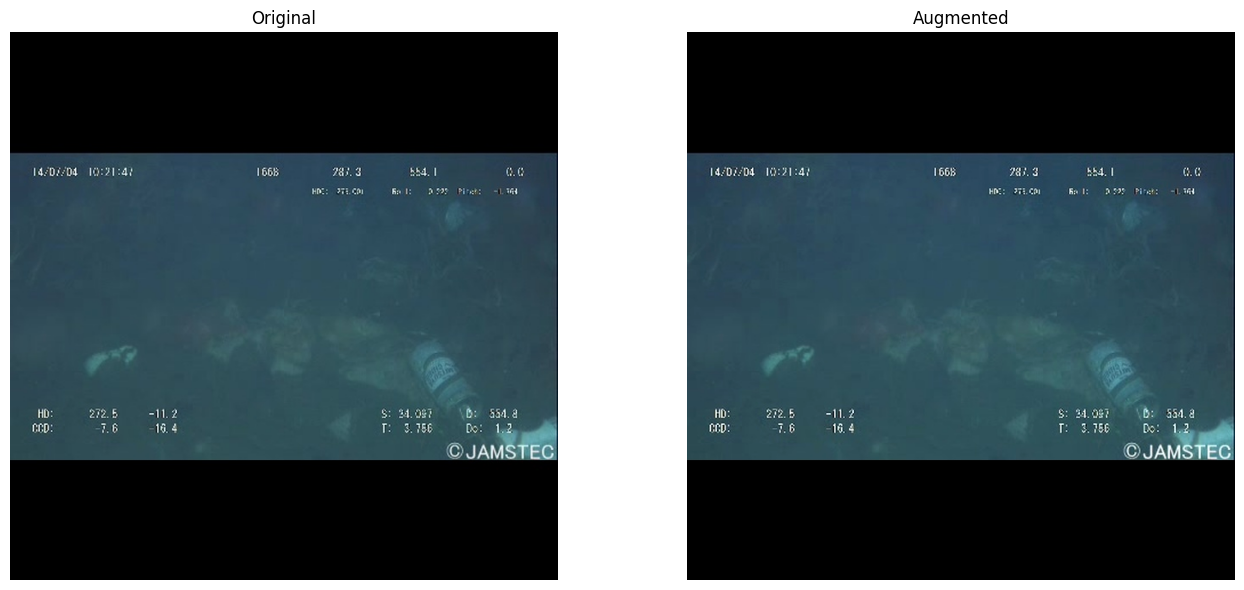

Original boxes: 1
Augmented boxes: 1


In [22]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

train_images = list(
    Path("/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/images/train").glob("*.jpg")
)

img_path = train_images[0]
img = cv2.imread(str(img_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

label_path = Path(
    "/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset/labels/train"
) / (img_path.stem + ".txt")

boxes = []
class_labels = []

with open(label_path, "r") as f:
    for line in f:
        values = line.strip().split()
        if len(values) >= 5:
            class_labels.append(int(values[0]))
            boxes.append([float(x) for x in values[1:5]])

augmented = train_augmentations(
    image=img,
    bboxes=boxes,
    class_labels=class_labels
)

aug_img = augmented["image"]
aug_boxes = augmented["bboxes"]
aug_labels = augmented["class_labels"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(aug_img)
axes[1].set_title("Augmented")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original boxes:", len(boxes))
print("Augmented boxes:", len(aug_boxes))

In [23]:
import os
import shutil
from pathlib import Path
import cv2
import random

SRC = Path("/kaggle/input/datasets/hanishkavya/trashcan/yolo_dataset")
DST = Path("/kaggle/working/trashcan_augmented")

(DST/"images/train").mkdir(parents=True, exist_ok=True)
(DST/"labels/train").mkdir(parents=True, exist_ok=True)
(DST/"images/val").mkdir(parents=True, exist_ok=True)
(DST/"labels/val").mkdir(parents=True, exist_ok=True)

# Copy validation unchanged
for p in (SRC/"images/val").glob("*.jpg"):
    shutil.copy2(p, DST/"images/val"/p.name)

for p in (SRC/"labels/val").glob("*.txt"):
    shutil.copy2(p, DST/"labels/val"/p.name)

print("Validation copied unchanged.")

Validation copied unchanged.


In [24]:
random.seed(42)

train_img_dir = SRC/"images/train"
train_lbl_dir = SRC/"labels/train"

train_images = list(train_img_dir.glob("*.jpg"))

for i, img_path in enumerate(train_images):

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    label_path = train_lbl_dir/(img_path.stem + ".txt")

    boxes = []
    class_labels = []

    with open(label_path, "r") as f:
        for line in f:
            v = line.strip().split()
            if len(v) >= 5:
                class_labels.append(int(v[0]))
                boxes.append([float(x) for x in v[1:5]])

    augmented = train_augmentations(
        image=img,
        bboxes=boxes,
        class_labels=class_labels
    )

    aug_img = cv2.cvtColor(augmented["image"], cv2.COLOR_RGB2BGR)

    # Save augmented image
    out_img = DST/"images/train"/img_path.name
    cv2.imwrite(str(out_img), aug_img)

    # Save transformed labels
    out_lbl = DST/"labels/train"/label_path.name

    with open(out_lbl, "w") as f:
        for cls, box in zip(
            augmented["class_labels"],
            augmented["bboxes"]
        ):
            f.write(
                f"{cls} {box[0]:.6f} {box[1]:.6f} "
                f"{box[2]:.6f} {box[3]:.6f}\n"
            )

    if (i + 1) % 500 == 0:
        print(f"Processed {i+1}/{len(train_images)}")

print("Training augmentation completed.")

Processed 500/5177
Processed 1000/5177
Processed 1500/5177
Processed 2000/5177
Processed 2500/5177
Processed 3000/5177
Processed 3500/5177
Processed 4000/5177
Processed 4500/5177
Processed 5000/5177
Training augmentation completed.


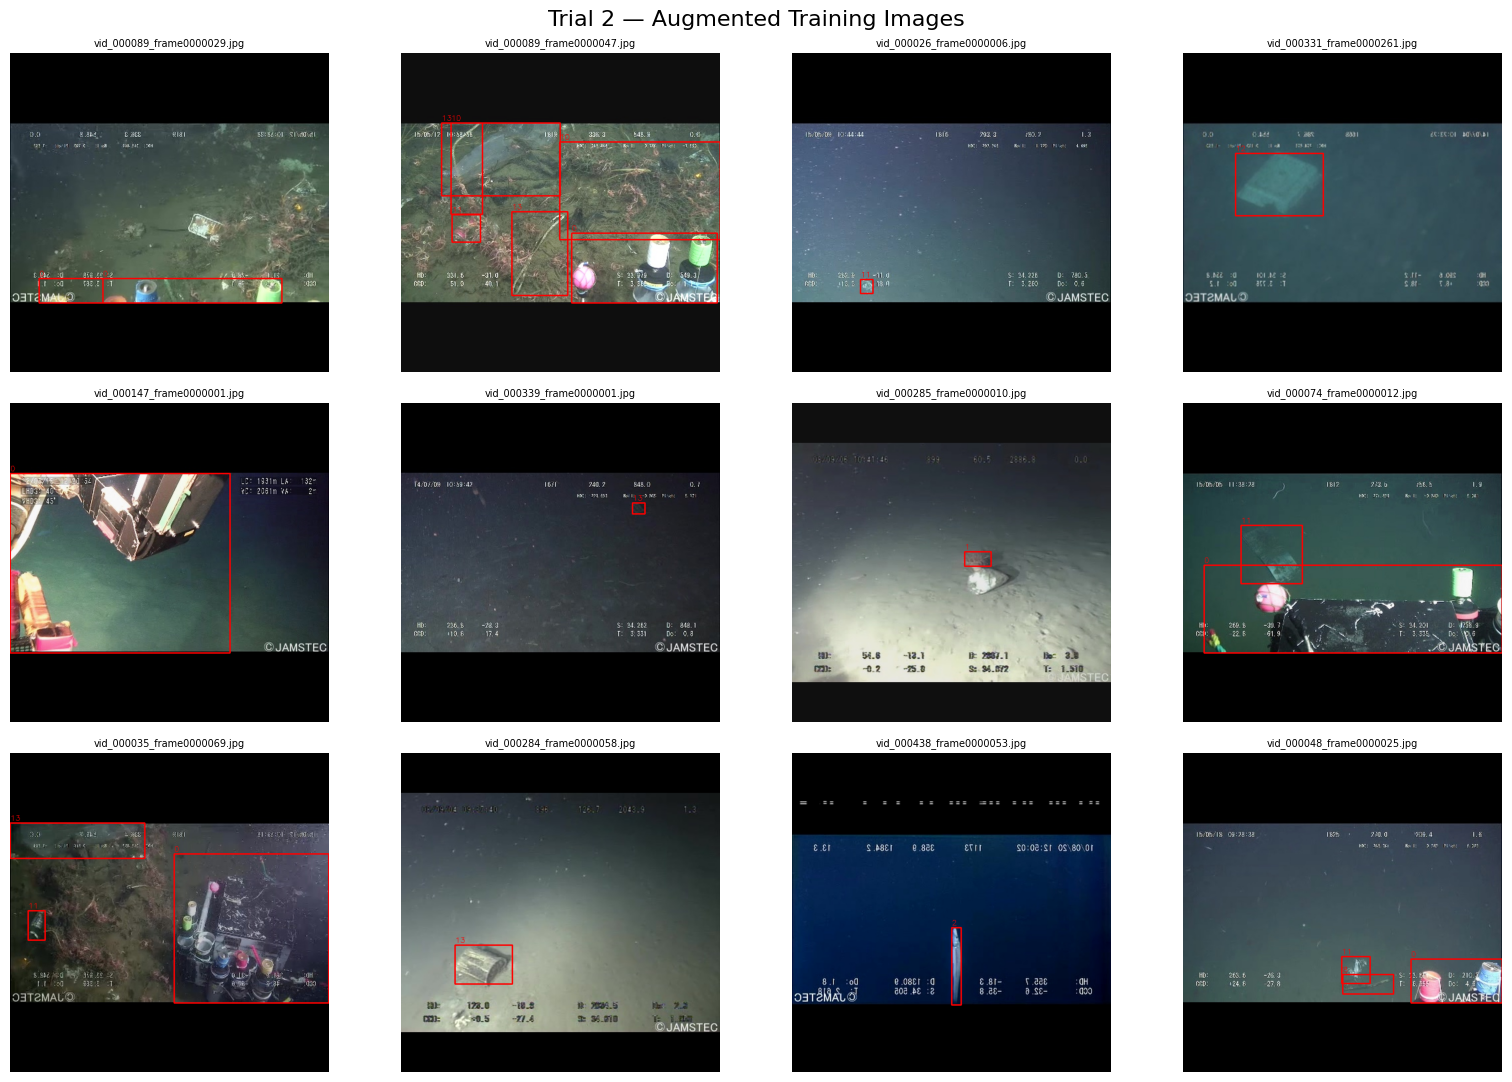

In [25]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import random

IMG_DIR = DST / "images/train"
LBL_DIR = DST / "labels/train"

images = list(IMG_DIR.glob("*.jpg"))

random.seed(42)
selected = random.sample(images, 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for ax, img_path in zip(axes, selected):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    label_path = LBL_DIR / (img_path.stem + ".txt")

    h, w = img.shape[:2]

    if label_path.exists():
        with open(label_path) as f:
            for line in f:
                v = line.strip().split()

                if len(v) < 5:
                    continue

                cls, xc, yc, bw, bh = map(float, v[:5])

                x1 = int((xc - bw/2) * w)
                y1 = int((yc - bh/2) * h)
                x2 = int((xc + bw/2) * w)
                y2 = int((yc + bh/2) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(
                    img,
                    str(int(cls)),
                    (x1, max(15, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 0, 0),
                    1
                )

    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=7)
    ax.axis("off")

plt.suptitle("Trial 2 — Augmented Training Images", fontsize=16)
plt.tight_layout()
plt.show()

In [27]:
from pathlib import Path

AUG_PATH = Path("/kaggle/working/trashcan_augmented")
TRIAL2_YAML = Path("/kaggle/working/trial2_data.yaml")

yaml_text = f"""path: {AUG_PATH}
train: images/train
val: images/val
nc: 16
names:
- rov
- plant
- animal_fish
- animal_starfish
- animal_shells
- animal_crab
- animal_eel
- animal_etc
- trash_etc
- trash_fabric
- trash_fishing_gear
- trash_metal
- trash_paper
- trash_plastic
- trash_rubber
- trash_wood
"""

TRIAL2_YAML.write_text(yaml_text)

print(TRIAL2_YAML.read_text())

path: /kaggle/working/trashcan_augmented
train: images/train
val: images/val
nc: 16
names:
- rov
- plant
- animal_fish
- animal_starfish
- animal_shells
- animal_crab
- animal_eel
- animal_etc
- trash_etc
- trash_fabric
- trash_fishing_gear
- trash_metal
- trash_paper
- trash_plastic
- trash_rubber
- trash_wood



In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

results = model.train(
    data=str(TRIAL2_YAML),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    pretrained=True,

    # Disable Ultralytics built-in augmentation
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    fliplr=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    erasing=0.0,

    project="/kaggle/working/yolo_refinement",
    name="trial2_mild_aug"
)

Ultralytics 8.4.146 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/trial2_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=trial2_mild_aug, nbs=64, nms=None, opset=Non